In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [2]:
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import confusion_matrix, recall_score, accuracy_score, precision_score

RANDOM_SEED = 2021
TEST_PCT = 0.3
LABELS = ["Normal", "Fraud"]

In [4]:
dataset = pd.read_csv("creditcard.csv")

# dataset.head

print(list(dataset.columns))

dataset.describe()

['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,...,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000
mean,49930.045000,0.097829,0.082349,-0.023773,0.045190,-0.152221,0.127334,-0.023342,-0.123021,-0.094199,...,0.075721,0.146957,0.002825,-0.121531,0.036335,0.030579,-0.083904,-0.039237,90.080293,0.050000
std,28308.854204,1.237764,1.230044,1.270749,1.139033,1.064768,1.212544,1.172339,1.050571,1.018540,...,1.044013,1.107388,1.448119,1.139396,1.151437,1.220999,1.342534,1.078977,104.643969,0.218492
min,916.000000,-3.463349,-5.202362,-4.779762,-4.431842,-5.031874,-4.802423,-3.681609,-3.483337,-3.019512,...,-2.906988,-2.854627,-7.530345,-4.841709,-3.208460,-4.211626,-9.758576,-3.899719,0.099970,0.000000
25%,25071.250000,-0.698816,-0.694553,-0.768311,-0.649415,-0.714966,-0.623994,-0.708941,-0.880160,-0.718198,...,-0.650376,-0.532817,-0.630170,-0.976725,-0.791476,-0.664623,-0.741526,-0.686033,29.890266,0.000000
50%,49983.000000,0.032835,-0.018552,-0.063920,0.050069,-0.184731,0.204351,-0.011756,-0.160513,-0.025231,...,0.066509,0.162089,0.009651,-0.134028,-0.014437,0.081287,0.017165,-0.022198,69.071653,0.000000
75%,75229.250000,0.805068,0.749335,0.701528,0.818902,0.396679,0.779827,0.599588,0.539034,0.546137,...,0.774396,0.769283,0.676756,0.626533,0.843020,0.711184,0.605551,0.580355,121.397372,0.000000
max,99750.000000,5.793216,6.774799,5.875495,3.260687,2.367528,4.607164,6.204867,3.901936,3.087677,...,5.462696,5.228392,8.049370,3.338602,5.441568,5.183983,3.243093,3.706152,1005.316737,1.000000


Text(0, 0.5, 'Number of Observations')

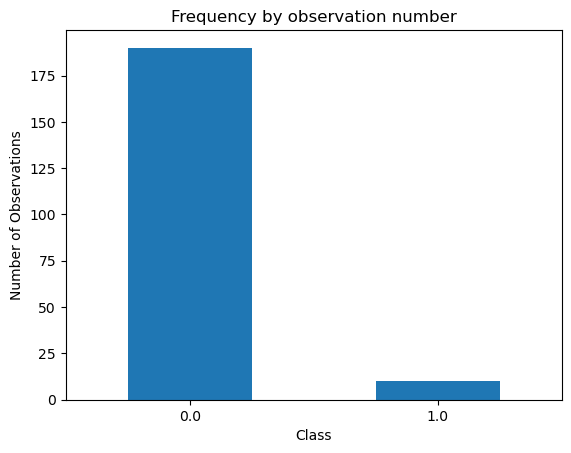

In [5]:
count_classes = dataset['Class'].value_counts()

count_classes.plot(kind='bar', rot=0)

plt.xticks(
    range(len(dataset['Class'].unique())),
    dataset.Class.unique()
)

plt.title("Frequency by observation number")

plt.xlabel("Class")

plt.ylabel("Number of Observations")

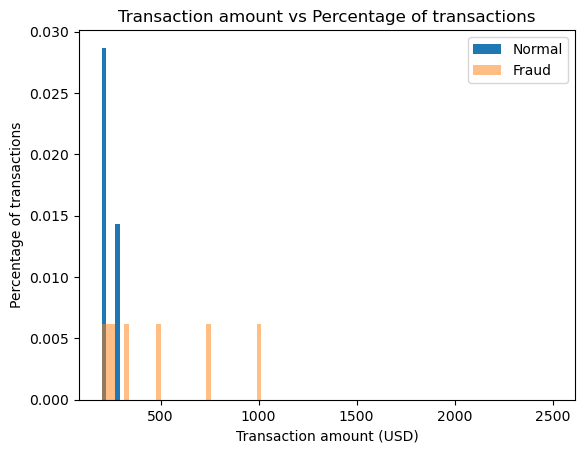

In [6]:
normal_dataset = dataset[dataset.Class == 0]

fraud_dataset = dataset[dataset.Class == 1]

bins = np.linspace(200, 2500, 100)

plt.hist(
    normal_dataset.Amount,
    bins=bins,
    alpha=1,
    density=True,
    label='Normal'
)

plt.hist(
    fraud_dataset.Amount,
    bins=bins,
    alpha=0.5,
    density=True,
    label='Fraud'
)

plt.legend(loc='upper right')

plt.title("Transaction amount vs Percentage of transactions")

plt.xlabel("Transaction amount (USD)")

plt.ylabel("Percentage of transactions")

plt.show()

In [7]:
sc = StandardScaler()

dataset['Time'] = sc.fit_transform(
    dataset['Time'].values.reshape(-1, 1)
)

dataset['Amount'] = sc.fit_transform(
    dataset['Amount'].values.reshape(-1, 1)
)

In [9]:
raw_data = dataset.values

labels = raw_data[:, -1]

data = raw_data[:, 0:-1]

In [10]:
train_data, test_data, train_labels, test_labels = train_test_split(
    data,
    labels,
    test_size=0.2,
    random_state=2021
)

In [11]:
min_val = tf.reduce_min(train_data)

max_val = tf.reduce_max(train_data)

train_data = (train_data - min_val) / (max_val - min_val)

test_data = (test_data - min_val) / (max_val - min_val)

train_data = tf.cast(train_data, tf.float32)

test_data = tf.cast(test_data, tf.float32)

In [12]:
train_labels = train_labels.astype(bool)
test_labels = test_labels.astype(bool)
normal_train_data = train_data[~train_labels]
normal_test_data = test_data[~test_labels]
fraud_train_data = train_data[train_labels]
fraud_test_data = test_data[test_labels]
print(" No. of records in Fraud Train Data=",len(fraud_train_data))
print(" No. of records in Normal Train data=",len(normal_train_data))
print(" No. of records in Fraud Test Data=",len(fraud_test_data))
print(" No. of records in Normal Test data=",len(normal_test_data))

 No. of records in Fraud Train Data= 8
 No. of records in Normal Train data= 152
 No. of records in Fraud Test Data= 2
 No. of records in Normal Test data= 38


In [13]:
nb_epoch = 50
batch_size = 64
input_dim = normal_train_data.shape[1] 
encoding_dim = 14
hidden_dim_1 = int(encoding_dim / 2)
hidden_dim_2=4  
learning_rate = 1e-7

In [14]:
input_layer = tf.keras.layers.Input(shape=(input_dim, ))
encoder = tf.keras.layers.Dense(encoding_dim, activation="tanh",                                
                        activity_regularizer=tf.keras.regularizers.l2(learning_rate))(input_layer)
encoder=tf.keras.layers.Dropout(0.2)(encoder)
encoder = tf.keras.layers.Dense(hidden_dim_1, activation='relu')(encoder)
encoder = tf.keras.layers.Dense(hidden_dim_2, activation=tf.nn.leaky_relu)(encoder)
decoder = tf.keras.layers.Dense(hidden_dim_1, activation='relu')(encoder)
decoder=tf.keras.layers.Dropout(0.2)(decoder)
decoder = tf.keras.layers.Dense(encoding_dim, activation='relu')(decoder)
decoder = tf.keras.layers.Dense(input_dim, activation='tanh')(decoder)
autoencoder = tf.keras.Model(inputs=input_layer, outputs=decoder)
autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 30)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 14)                  │             434 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 14)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 7)                   │             105 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 4)                   │              32 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 7)                   │              35 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 7)                   │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 14)                  │             112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 30)                  │             450 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,168 (4.56 KB)

 Trainable params: 1,168 (4.56 KB)

 Non-trainable params: 0 (0.00 B)

In [15]:
cp = tf.keras.callbacks.ModelCheckpoint(filepath="autoencoder_fraud.h5",
mode='min', monitor='val_loss', verbose=2, save_best_only=True)
early_stop = tf.keras.callbacks.EarlyStopping(
monitor='val_loss',
min_delta=0.0001,
patience=10,
verbose=1, 
mode='min',
restore_best_weights=True)


In [17]:
autoencoder.compile(metrics=['accuracy'],
loss='mean_squared_error',
optimizer='adam')

In [18]:
history = autoencoder.fit(normal_train_data, normal_train_data,
epochs=nb_epoch,
batch_size=batch_size,
shuffle=True,
validation_data=(test_data, test_data),
verbose=1,
callbacks=[cp, early_stop]
).history

Epoch 1/50
1/3 ━━━━━━━━━━━━━━━━━━━━ 6s 3s/step - accuracy: 0.0625 - loss: 0.2799
Epoch 1: val_loss improved from None to 0.27472, saving model to autoencoder_fraud.h5



Epoch 1: finished saving model to autoencoder_fraud.h5
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 274ms/step - accuracy: 0.0329 - loss: 0.2795 - val_accuracy: 0.0250 - val_loss: 0.2747
Epoch 2/50
1/3 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.0156 - loss: 0.2764
Epoch 2: val_loss improved from 0.27472 to 0.27119, saving model to autoencoder_fraud.h5



Epoch 2: finished saving model to autoencoder_fraud.h5
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.0066 - loss: 0.2752 - val_accuracy: 0.0250 - val_loss: 0.2712
Epoch 3/50
1/3 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.0000e+00 - loss: 0.2719
Epoch 3: val_loss improved from 0.27119 to 0.26752, saving model to autoencoder_fraud.h5



Epoch 3: finished saving model to autoencoder_fraud.h5
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - accuracy: 0.0263 - loss: 0.2715 - val_accuracy: 0.0250 - val_loss: 0.2675
Epoch 4/50
1/3 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.0156 - loss: 0.2688
Epoch 4: val_loss improved from 0.26752 to 0.26373, saving model to autoencoder_fraud.h5



Epoch 4: finished saving model to autoencoder_fraud.h5
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.0132 - loss: 0.2677 - val_accuracy: 0.0250 - val_loss: 0.2637
Epoch 5/50
1/3 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.0156 - loss: 0.2645
Epoch 5: val_loss improved from 0.26373 to 0.25978, saving model to autoencoder_fraud.h5



Epoch 5: finished saving model to autoencoder_fraud.h5
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.0197 - loss: 0.2637 - val_accuracy: 0.0250 - val_loss: 0.2598
Epoch 6/50
1/3 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.0156 - loss: 0.2618
Epoch 6: val_loss improved from 0.25978 to 0.25562, saving model to autoencoder_fraud.h5


... (41 outputs left out)


Epoch 47: finished saving model to autoencoder_fraud.h5
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.0395 - loss: 0.0260 - val_accuracy: 0.1000 - val_loss: 0.0141
Epoch 48/50
1/3 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.0625 - loss: 0.0226
Epoch 48: val_loss improved from 0.01409 to 0.01349, saving model to autoencoder_fraud.h5



Epoch 48: finished saving model to autoencoder_fraud.h5
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.0329 - loss: 0.0220 - val_accuracy: 0.1000 - val_loss: 0.0135
Epoch 49/50
1/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.0781 - loss: 0.0194
Epoch 49: val_loss improved from 0.01349 to 0.01327, saving model to autoencoder_fraud.h5



Epoch 49: finished saving model to autoencoder_fraud.h5
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.0526 - loss: 0.0201 - val_accuracy: 0.1000 - val_loss: 0.0133
Epoch 50/50
1/3 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.0625 - loss: 0.0225
Epoch 50: val_loss improved from 0.01327 to 0.01303, saving model to autoencoder_fraud.h5



Epoch 50: finished saving model to autoencoder_fraud.h5
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.0329 - loss: 0.0196 - val_accuracy: 0.1000 - val_loss: 0.0130
Restoring model weights from the end of the best epoch: 50.


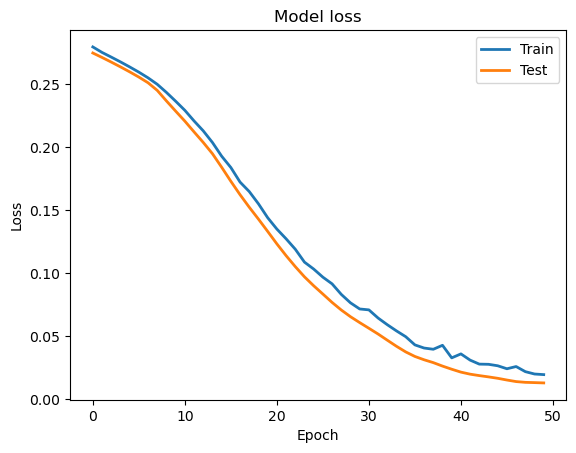

In [19]:
plt.plot(history['loss'], linewidth=2, label='Train')
plt.plot(history['val_loss'], linewidth=2, label='Test')
plt.legend(loc='upper right')
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.show()

In [20]:
test_x_predictions = autoencoder.predict(test_data)
mse = np.mean(np.power(test_data - test_x_predictions, 2), axis=1)
error_df = pd.DataFrame({'Reconstruction_error': mse,
'True_class': test_labels})

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step


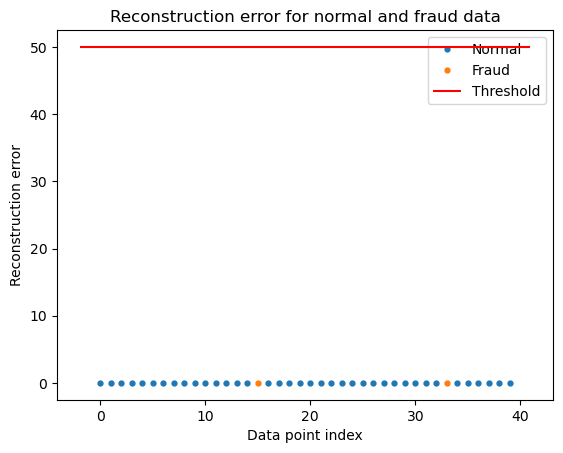

In [22]:
threshold_fixed = 50
groups = error_df.groupby('True_class')
fig, ax = plt.subplots()
for name, group in groups:
    ax.plot(group.index, group.Reconstruction_error, marker='o', ms=3.5, linestyle='',
    label= "Fraud" if name == 1 else "Normal")
ax.hlines(threshold_fixed, ax.get_xlim()[0], ax.get_xlim()[1], colors="r", zorder=100, label='Threshold')
ax.legend()
plt.title("Reconstruction error for normal and fraud data")
plt.ylabel("Reconstruction error")
plt.xlabel("Data point index")
plt.show();


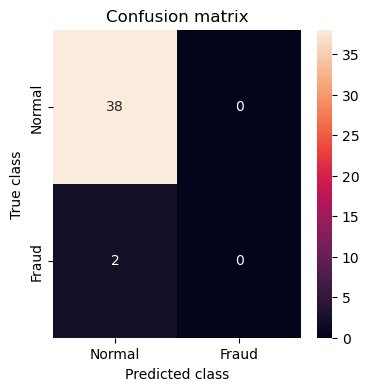

 Accuracy:  0.95
 Recall:  0.0
 Precision:  0.0


C:\Users\DELL\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [23]:
threshold_fixed =52
pred_y = [1 if e > threshold_fixed else 0 for e in error_df.Reconstruction_error.values]
error_df['pred'] =pred_y
conf_matrix = confusion_matrix(error_df.True_class, pred_y)
plt.figure(figsize=(4, 4))
sns.heatmap(conf_matrix, xticklabels=LABELS, yticklabels=LABELS, annot=True, fmt="d");
plt.title("Confusion matrix")
plt.ylabel('True class')
plt.xlabel('Predicted class')
plt.show()
print(" Accuracy: ",accuracy_score(error_df['True_class'], error_df['pred']))
print(" Recall: ",recall_score(error_df['True_class'], error_df['pred']))
print(" Precision: ",precision_score(error_df['True_class'], error_df['pred']))